# Visualize Model Predictions

This notebook loads a trained model and visualizes its predictions on a new sample.

In [1]:
import sys
import json
import random
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from plot_utils_era5 import *

import napari
from scipy.interpolate import griddata
from pathlib import Path



project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(Path.cwd().parent / 'scripts'))

sys.path.append(f"{project_root}src/")
# Import utilities
from utilities import KernelNN, KernelNN_subgraph, setup_device, get_output_affinities
from plot_utilities import plot_results_napari, plot_results_matplotlib

# Device setup
device = setup_device()
print(f'Using device: {device}')

Using device: mps


In [4]:
os.system("rsync -r springfield:~/new/NOFE/ERA5/trained_models/* ../trained_models/")

rsync error: received SIGINT, SIGTERM, or SIGHUP (code 20) at rsync.c(763) [Receiver=3.4.1]


5120

In [2]:
# choose data
model_type = 'subgraph'


# ---------------------------------------------------------------------------
sys.path.append(f"{project_root}/ERA5/scripts/")
from utilities_era5 import ERA5_Graph_Generator as Data_Generator


# Paths
trained_models_path = project_root / 'ERA5' / 'trained_models' / model_type
training_logs_path = trained_models_path / 'logs'
data_path = project_root.parent / 'ERA5' / 'data'  # Adjust if needed

print('Available models:\n')
files = sorted(os.listdir(trained_models_path), reverse=True)

for i, f in enumerate(files):
    if Path(f).suffix == ".pth":
        print(f'[{i}] {f}')



using Device: mps
Available models:

[0] test_model-subgraph-2026-04-12_t23-27-46.pth
[1] subgraph_tkernel_base_d3_2026-04-27_t20-27-49.pth
[2] subgraph_tkernel_base_d3_2026-04-26_t12-02-03.pth
[3] subgraph_tkernel_base_d3_2026-04-26_t12-00-40.pth
[4] subgraph_tkernel_base_d3_2026-04-25_t14-53-56.pth
[5] subgraph_tkernel_base_d3_2026-04-25_t12-16-11.pth
[6] subgraph_tkernel_base_d3_2026-04-25_t11-26-08.pth
[7] subgraph_tkernel_base2_d2_2026-04-25_t13-59-37.pth
[8] subgraph_tkernel_base2_d2_2026-04-25_t13-46-23.pth
[9] subgraph_fixcrop_median_testmodel9_2026-04-20_t07-50-21.pth
[10] subgraph_fixcrop_median_testmodel7_2026-04-19_t15-48-03.pth
[11] subgraph_fixcrop_median_testmodel5_2026-04-19_t15-52-52.pth
[12] subgraph_fixcrop_median_testmodel5_2026-04-18_t08-13-55.pth
[13] subgraph_fixcrop_median_testmodel4_2026-04-17_t17-02-43.pth
[14] subgraph_fixcrop_median_testmodel3_2026-04-17_t17-02-43.pth
[15] subgraph_fixcrop_median_testmodel2_2026-04-19_t15-50-36.pth
[16] subgraph_fixcrop_medi

## 2. Load Model and Configuration

In [62]:
# Set model ID
model_id = 'subgraph_tkernel_base2_d2_2026-04-25_t13-59-37' #'subgraph_tkernel_base_d3_2026-04-26_t12-02-03'  



# ---------------------------------------------------------------------------
if model_id.endswith('.pth'):
    model_id = model_id[:-4]

# Load full configuration (includes model, dataset, and training configs)
config_path = f'{training_logs_path}/configs/{model_id}.json'
with open(config_path, 'r') as f:
    config = json.load(f)

# Load loss records
loss_df = pd.read_csv(f'{training_logs_path}/loss_records/{model_id}.csv')

print('Configuration:')
for key, value in config.items():
    print(f'  {key}: {value}')

print(f'\Training completed {len(loss_df)} epochs')
print(f'Final training loss: {loss_df["loss"].iloc[-1]:.4f}')
print(f'Final validation loss: {loss_df["val_loss"].iloc[-1]:.4f}')

Configuration:
  model_config_path: ERA5/configurations/subgraph/model_configs/base2_d2.json
  dataset_id: sub_fixcrop_median_woPos_tkernel
  dataset_path: ERA5/datasets/subgraph
  learning_rate: 0.001
  scheduler_step: 2
  scheduler_gamma: 0.5
  epochs: 25
  random_seed: 42
  use_gradient_clipping: True
  track_gradients: True
  checkpoint_every: 5
  width: 64
  ker_width: 64
  depth: 2
  input_node_features: 11
  output_node_features: 11
  edge_attr: 7
  out_width: 3
  data_folder_path: ../data/
  dataset_save_path: ../datasets/subgraph/
  lat_min: 30
  lat_max: 70
  lon_min: -10
  lon_max: 30
  N_in_min: 100
  N_in_max: 5000
  N_out_min: 1000
  N_out_max: 10000
  k_in: 5
  k_out: 5
  k_cross: 5
  perplexity: 20
  input_sampling_method: random
  output_sampling_method: random
  train_date_start_end: ['2018-01-01', '2018-12-31']
  test_date_start_end: ['2019-01-01', '2019-01-31']
  train_samples_per_date: 10
  test_samples_per_date: 2
  feature_mode: channel_only
  interpolate_graph_f

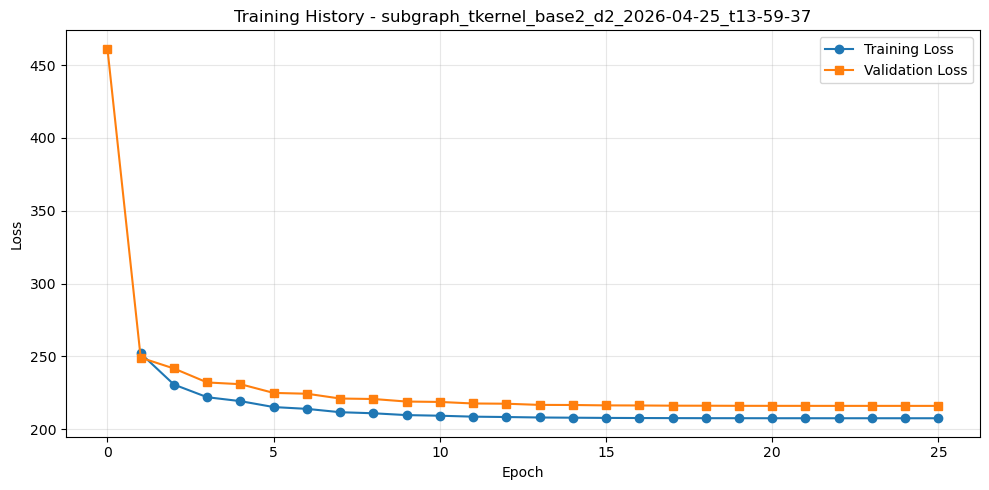

In [63]:
# Plot training history
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(loss_df['epoch'], loss_df['loss'], label='Training Loss', marker='o')
ax.plot(loss_df['epoch'], loss_df['val_loss'], label='Validation Loss', marker='s')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title(f'Training History - {model_id}')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [64]:
data_folder_path = config["data_folder_path"]
dataset_save_path = config["dataset_save_path"]
lat_min = config["lat_min"]
lat_max = config["lat_max"]
lon_min = config["lon_min"]
lon_max = config["lon_max"]

k_in = config["k_in"]
k_out = config["k_out"]
k_cross = config["k_cross"]
perplexity = config["perplexity"]
input_sampling_method = config["input_sampling_method"]
output_sampling_method = config["output_sampling_method"]
train_date_start_end = config["train_date_start_end"]
test_date_start_end = config["test_date_start_end"]
train_samples_per_date = config["train_samples_per_date"]
test_samples_per_date = config["test_samples_per_date"]
feature_mode = config["feature_mode"]
interpolate_graph_features = config["interpolate_graph_features"]
vars = config["vars"]


In [65]:
model = KernelNN_subgraph(
    width=config['width'],  # number features per node after lifting
    ker_width=config['ker_width'],  # dimension of single kernel layer
    depth=config['depth'],  # number of graph layers / message passings
    ker_in=config['edge_attr'],  # number of edge features
    known_node_dim=config['input_node_features'],  # only needed when lifting is applied within model
    unknown_node_dim=config['output_node_features'],
    out_width=config['out_width']
).to(device)



# Load trained weights
model_path = f'{trained_models_path}/{model_id}.pth'
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

print(f'Model loaded: {model_id}')
print(f'Total parameters: {sum(p.numel() for p in model.parameters()):,}')

Model loaded: subgraph_tkernel_base2_d2_2026-04-25_t13-59-37
Total parameters: 551,875


## 3. Create New Sample

Use the same functionality as dataset creation to generate a single sample.

In [89]:
date = "2019-01-11"

bbox = lon_min, lat_min, lon_max, lat_max
Generator = Data_Generator(data_path)
Generator.load_data(bbox=bbox, vars=vars, filename=f'{date}.nc')

In [112]:
N_in = 1000
input_sampling_method = "regular_subset"

in_graph = Generator.sample_graph(N=N_in, k=k_in, perplexity=perplexity, sampling_method=input_sampling_method, gen_feature_mode=feature_mode)
full_data = Generator.sample_graph(N=100000, k=0, perplexity=0, sampling_method='random', gen_feature_mode=feature_mode)

requested number of points larger then dataset
-> return full dataset of 25921 points.


In [129]:
N_out = 1000
output_sampling_method = "regular_subset"

out_graph = Generator.sample_graph(N=N_out, k=k_out, perplexity=perplexity, sampling_method=output_sampling_method, gen_feature_mode=feature_mode)
#out_graph = Generator.synthetic_graph(N=N_out, k=k_out, gen_feature_mode=feature_mode)
cross_graph = Generator.connect_graphs(in_graph=in_graph, out_graph=out_graph, k_cross=k_cross)
cross_graph["x"] = Generator.construct_output_node_features(cross_graph=cross_graph, interpolate=interpolate_graph_features, gen_feature_mode=feature_mode)
sample = cross_graph.to(device)

In [130]:
figsize = (5, 5)

In [131]:
print('predict results')
output = model(sample).detach().cpu().numpy()

predict results


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.022988991392962968..1.0158793722332962].


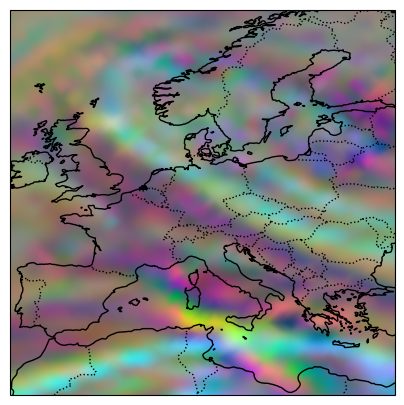

In [132]:
locations = pd.DataFrame({"lat": sample.target.meta.gps[:,0], "lon": sample.target.meta.gps[:,1]})

res_model = pd.DataFrame(
    {
        "x1": output[:, 0],
        "x2": output[:, 1],
        "x3": output[:, 2],
    }
)
res_model = pd.concat([locations, res_model], axis=1)

fig = rgb(res_model, figsize=figsize)

### PCA input points

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0028498164992498626..1.0910169803952934].


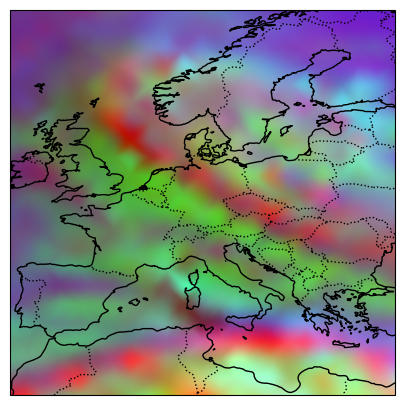

In [80]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

# example input (replace with your array)
X = sample.source.x.detach().cpu().numpy() # shape: (samples, features)

# apply PCA to reduce to 3 dimensions
pca = PCA(n_components=3)
X_reduced = pca.fit_transform(X)

locations = pd.DataFrame({"lat": sample.source.meta.gps[:,0], "lon": sample.source.meta.gps[:,1]})


# create pandas DataFrame
res_pca= pd.DataFrame(X_reduced, columns=["x1", "x2", "x3"])
res_pca = pd.concat([locations, res_pca], axis=1)

fig = rgb(res_pca, figsize=figsize)

## PCA output points

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.010201985846454464..1.0142602121897193].


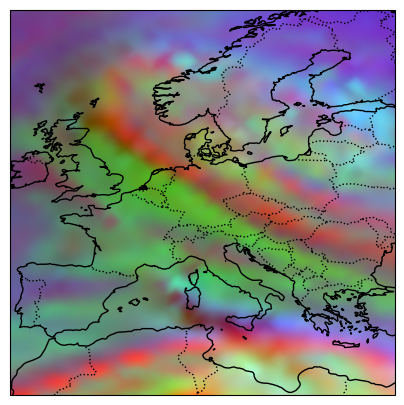

In [81]:
from sklearn.decomposition import PCA

# example input (replace with your array)
X = sample.target.meta.x_true.detach().cpu().numpy() # shape: (samples, features)

# apply PCA to reduce to 3 dimensions
pca = PCA(n_components=3)
X_reduced = pca.fit_transform(X)

locations_out = pd.DataFrame({"lat": sample.target.meta.gps[:,0], "lon": sample.target.meta.gps[:,1]})


# create pandas DataFrame
res_pca= pd.DataFrame(X_reduced, columns=["x1", "x2", "x3"])
res_pca = pd.concat([locations_out, res_pca], axis=1)

fig = rgb(res_pca, figsize=figsize)

## PCA all points

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.005417009650789044..1.0058497583620125].


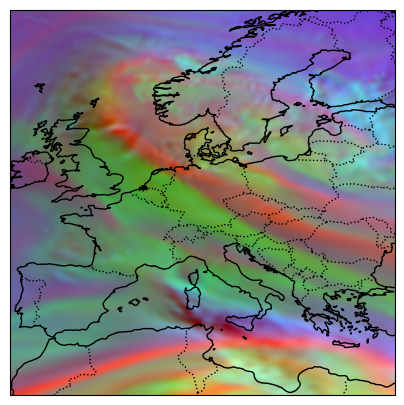

In [84]:
from sklearn.decomposition import PCA

# example input (replace with your array)
X =full_data.x.detach().cpu().numpy() # shape: (samples, features)

# apply PCA to reduce to 3 dimensions
pca = PCA(n_components=3)
X_reduced = pca.fit_transform(X)

locations_out = pd.DataFrame({"lat": full_data.meta.gps[:,0], "lon": full_data.meta.gps[:,1]})


# create pandas DataFrame
res_pca= pd.DataFrame(X_reduced, columns=["x1", "x2", "x3"])
res_pca = pd.concat([locations_out, res_pca], axis=1)

fig = rgb(res_pca, figsize=figsize)